# #Importing the Libraries

In [3]:
import cv2
import matplotlib.pyplot as plt
import numpy as np
import torch
from ultralytics import YOLO

# #Importing YOLO Model

In [4]:
from ultralytics import YOLO
model = YOLO("yolov8n.pt")
model = model = YOLO("yolov8n.pt")

# #Examples of Two images working in YOLO model

In [5]:
results = model("https://ultralytics.com/images/zidane.jpg")
results[0].show()


Found https://ultralytics.com/images/zidane.jpg locally at zidane.jpg
image 1/1 /home/vatsal/PROGRAMMING/Machine Learning/Drowsiness_Detection/zidane.jpg: 384x640 2 persons, 1 tie, 40.1ms
Speed: 1.2ms preprocess, 40.1ms inference, 1.0ms postprocess per image at shape (1, 3, 384, 640)


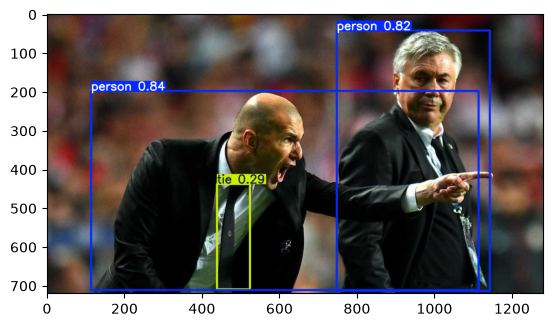

In [6]:
rgb_img = cv2.cvtColor(results[0].plot(), cv2.COLOR_BGR2RGB)
plt.imshow(rgb_img)
plt.show()

In [7]:
img2 = model('https://media.istockphoto.com/id/159406920/photo/aerial-view-of-cars-in-traffic.jpg?s=1024x1024&w=is&k=20&c=pEBHcQ14J3IGPxYn0wWQdLLruc7MLTe_3lJ1QN5IhMk=')


Found https://media.istockphoto.com/id/159406920/photo/aerial-view-of-cars-in-traffic.jpg locally at aerial-view-of-cars-in-traffic.jpg
image 1/1 /home/vatsal/PROGRAMMING/Machine Learning/Drowsiness_Detection/aerial-view-of-cars-in-traffic.jpg: 448x640 40 cars, 1 truck, 56.3ms
Speed: 1.5ms preprocess, 56.3ms inference, 1.0ms postprocess per image at shape (1, 3, 448, 640)


In [8]:
img2[0].show()

# #Real Time Detections

In [9]:
if 'cap' in locals() and cap is not None:
    cap.release()
cv2.destroyAllWindows()

In [10]:
import cv2
from ultralytics import YOLO

model = YOLO("yolov8n.pt")
cap = cv2.VideoCapture(0, cv2.CAP_V4L2) #uf we paste a video file path here that will work aswell

while cap.isOpened():
    ret, frame = cap.read() #basically return value + frame
    if not ret: break

    #Storing the result
    results = model(frame,verbose=False)[0]
    #Extract and print data for each object detected
    for box in results.boxes:
        classID = int(box.cls[0])
        label = model.names[classID]
        conf = float(box.conf[0])
        coordinate  = box.xyxy[0].tolist()
        print(f"label:{label}|conf:{conf:.2f}|box:{coordinate}")
    cv2.imshow("YOLOv8", results.plot())
    if cv2.waitKey(1) & 0xFF == ord("q"): break

cap.release()
cv2.destroyAllWindows()

label:person|conf:0.87|box:[208.68524169921875, 190.27735900878906, 629.0037231445312, 479.7236328125]
label:skateboard|conf:0.28|box:[148.63735961914062, 293.09136962890625, 219.00595092773438, 427.37884521484375]
label:person|conf:0.86|box:[209.5366668701172, 190.68276977539062, 632.0021362304688, 479.5675964355469]
label:person|conf:0.88|box:[209.581298828125, 191.00894165039062, 635.6668090820312, 479.7333679199219]
label:person|conf:0.88|box:[210.1641845703125, 191.23373413085938, 633.943359375, 479.7078552246094]
label:person|conf:0.87|box:[210.50408935546875, 190.98272705078125, 632.6619262695312, 479.7227783203125]
label:person|conf:0.85|box:[210.22735595703125, 191.75245666503906, 618.8409423828125, 479.743408203125]
label:person|conf:0.86|box:[209.01023864746094, 190.6258544921875, 598.1693115234375, 479.51171875]
label:bottle|conf:0.33|box:[617.22216796875, 353.5448913574219, 639.757080078125, 437.5674743652344]
label:person|conf:0.87|box:[210.4207763671875, 191.610961914062

# #Train on coustom Model 

In [25]:
if 'cap' in locals() and cap is not None:
    cap.release()
cv2.destroyAllWindows()

In [26]:
import cv2

for index in range(4):
    cap = cv2.VideoCapture(index, cv2.CAP_V4L2)
    if cap.isOpened():
        ret, frame = cap.read()
        if ret:
            print(f"Camera works on index {index}!")
            cap.release()
            break
        cap.release()
    else:
        print(f" Index {index} failed.")

[SUCCESS] Camera works on index 0!


In [27]:
import os
import time
import uuid
import cv2

labels = ['awake', 'drowsy']
number_images = 20

# 1. Create target directories
for label in labels:
    os.makedirs(os.path.join('data', 'images', label), exist_ok=True)

# 2. Open camera
cap = cv2.VideoCapture(0)

# 3. Capture image loop
for label in labels:
    print(f"Collecting images for {label}")
    time.sleep(5)

    for img_num in range(number_images):
        ret, frame = cap.read()

        imageName = os.path.join('data', 'images', label, f"{label}.{str(uuid.uuid1())}.jpg")
        cv2.imwrite(imageName, frame)
        cv2.imshow('Image Collection', frame)

        time.sleep(2)

        if cv2.waitKey(1) & 0xFF == ord('q'):
            break

cap.release()
cv2.destroyAllWindows()

In [29]:
!git clone https://github.com/HumanSignal/labelImg

Cloning into 'labelImg'...
remote: Enumerating objects: 2097, done.
remote: Total 2097 (delta 0), reused 0 (delta 0), pack-reused 2097 (from 1)
Receiving objects: 100% (2097/2097), 237.15 MiB | 10.11 MiB/s, done.
Resolving deltas: 100% (1221/1221), done.


In [32]:
!pip install pyqt5 lxml --upgrade
!cd labelImg && pyrcc5 -o libs/resources.py resources.qrc

In [46]:
!find data/ -maxdepth 3

data/
data/labels
data/labels/drowsy.f7744892-d24d-11f1-aac3-d0c1b539ba4a.xml
data/labels/train.cache
data/labels/awake.c6e87a6c-d24d-11f1-93d9-d0c1b539ba4a.xml
data/labels/val
data/labels/val/awake.d41c5360-d24d-11f1-96a4-d0c1b539ba4a.txt
data/labels/val/awake.d1b66c97-d24d-11f1-a3d3-d0c1b539ba4a.txt
data/labels/val/awake.cceaeef8-d24d-11f1-b66e-d0c1b539ba4a.txt
data/labels/val/drowsy.e7df5d4f-d24d-11f1-83fc-d0c1b539ba4a.txt
data/labels/val/drowsy.e912600a-d24d-11f1-b385-d0c1b539ba4a.txt
data/labels/val/drowsy.f8a74e2f-d24d-11f1-a804-d0c1b539ba4a.txt
data/labels/val/drowsy.f042933a-d24d-11f1-ae0f-d0c1b539ba4a.txt
data/labels/val/drowsy.f640eef9-d24d-11f1-b23e-d0c1b539ba4a.txt
data/labels/classes.txt
data/labels/train
data/labels/train/drowsy.f3db330e-d24d-11f1-ad74-d0c1b539ba4a.txt
data/labels/train/drowsy.e313aa02-d24d-11f1-9c55-d0c1b539ba4a.txt
data/labels/train/awake.d7b5456b-d24d-11f1-a718-d0c1b539ba4a.txt
data/labels/train/awake.c81e073b-d24d-11f1-8652-d0c1b539ba4a.txt
data/label

In [50]:
yaml_content = """path: /home/vatsal/PROGRAMMING/Machine Learning/Drowsiness_Detection/data
train: images/train
val: images/val

names:
  0: awake
  1: drowsy
"""

with open('dataset.yaml', 'w') as f:
    f.write(yaml_content)

print("[SUCCESS] dataset.yaml updated!")

[SUCCESS] dataset.yaml updated!


In [51]:
import os

base_labels = 'data/labels'

for root, _, files in os.walk(base_labels):
    for f in files:
        if f.endswith('.txt') and f != 'classes.txt':
            file_path = os.path.join(root, f)
            
            with open(file_path, 'r') as file:
                lines = file.readlines()
            
            new_lines = []
            for line in lines:
                parts = line.strip().split()
                if not parts:
                    continue
                
                # If filename starts with 'drowsy', assign class index 1; otherwise 0 (awake)
                target_class = '1' if f.startswith('drowsy') else '0'
                
                # Replace the old class ID (15/16) with the correct ID (0/1)
                parts[0] = target_class
                new_lines.append(" ".join(parts) + "\n")
            
            with open(file_path, 'w') as file:
                file.writelines(new_lines)

# Remove old dataset cache files so YOLO reads updated labels
for cache in ['data/labels/train.cache', 'data/labels/val.cache']:
    if os.path.exists(cache):
        os.remove(cache)

print("[SUCCESS] Fixed class IDs in all label files! You can now start training.")

[SUCCESS] Fixed class IDs in all label files! You can now start training.


In [52]:
from ultralytics import YOLO

model = YOLO('yolov8n.pt')

results = model.train(
    data='dataset.yaml',
    epochs=25,
    imgsz=640,
    batch=8,
    name='drowsiness_detection'
)

New https://pypi.org/project/ultralytics/8.4.191 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.189 🚀 Python-3.12.3 torch-2.14.1+cpu CPU (13th Gen Intel Core i5-1334U)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=dataset.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=25, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic

In [54]:
import os
import cv2
from ultralytics import YOLO

# Automatically locate the most recent best.pt weight file
weights_path = None
for root, dirs, files in os.walk('runs/detect'):
    if 'best.pt' in files:
        weights_path = os.path.join(root, 'best.pt')

if not weights_path:
    raise FileNotFoundError("[ERROR] Could not find 'best.pt' inside runs/detect/. Check your runs/ directory!")

print(f"[INFO] Found model weights at: {weights_path}")

# Load model and initialize webcam
model = YOLO(weights_path)
cap = cv2.VideoCapture(0)

print("[INFO] Webcam feed running. Focus the video popup window and press 'q' to exit.")

while cap.isOpened():
    ret, frame = cap.read()
    if not ret or frame is None:
        print("[ERROR] Failed to grab webcam frame.")
        break

    # Run inference
    results = model(frame, conf=0.5, verbose=False)

    # Annotate frame with bounding boxes & class labels
    annotated_frame = results[0].plot()

    cv2.imshow('Drowsiness Detector', annotated_frame)

    if cv2.waitKey(1) & 0xFF == ord('q'):
        break

cap.release()
cv2.destroyAllWindows()
print("[INFO] Stream closed successfully.")

[INFO] Found model weights at: runs/detect/drowsiness_detection-5/weights/best.pt
[INFO] Webcam feed running. Focus the video popup window and press 'q' to exit.
[INFO] Stream closed successfully.
